# 04 · Evaluation

**Goal.** Judge the models honestly on data they have never seen:

1. the **held-out test split** (latest 20% of household dates),
2. **another person's data** (personal finance, USA, USD),
3. **the student's own expenses** (Pakistan, PKR).

Then look at the mistakes, choose a confidence threshold for the app, and record the results for the model card.

*Numbers quoted in the text cells come from the reference run (Python 3.11, scikit-learn 1.9). With other library
versions or another operating system the code cells can differ in the third decimal; the code cells are always the truth.*

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import seaborn as sns

# One quiet style for every chart: light grid, no top/right frame, grey text.
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "grid.color": "#ebeae6", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12,
    "figure.dpi": 110})

import re

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict

from src import config, data, train as T
from src.features import INPUT_COLUMNS
from src.zero_shot import zero_shot_predict

household = data.load_source("household")
train, test = data.time_split(household)
eval_sets = {"household test": test,
             "personal finance": data.load_source("personal_finance"),
             "own expenses": data.load_source("own")}
candidates = joblib.load(T.CANDIDATES_PATH)
metadata = T.load_metadata()
chosen_name = metadata["model_name"]
chosen = candidates[chosen_name]
print(f"Chosen model (from notebook 03): {chosen_name} {metadata['settings']}")
print({name: len(df) for name, df in eval_sets.items()})

[map] household: dropped 444 of 2176 rows with no matching category
[clean] removed 159 empty-description rows and 0 exact duplicates
[map] personal_finance: dropped 84 of 688 rows with no matching category
[clean] removed 0 empty-description rows and 0 exact duplicates
[clean] removed 0 empty-description rows and 0 exact duplicates
Chosen model (from notebook 03): minilm_logreg {'C': 10, 'class_weight': 'balanced'}
{'household test': 315, 'personal finance': 604, 'own expenses': 5}


## 1 · Results on every evaluation set

In [2]:
def predictions(model_name: str, df: pd.DataFrame) -> list[str]:
    if model_name == "zero_shot":
        return zero_shot_predict(df.description.tolist())
    return list(candidates[model_name].predict(df[INPUT_COLUMNS]))

model_order = ["majority_baseline", "zero_shot", "tfidf_logreg", "minilm_logreg"]
rows = []
for set_name, df in eval_sets.items():
    for model_name in model_order:
        result = T.scores(df.category, predictions(model_name, df))
        rows.append({"eval set": set_name, "rows": len(df), "model": model_name} | result)
results = pd.DataFrame(rows)
config.REPORTS_DIR.mkdir(exist_ok=True)
results.round(3).to_csv(config.REPORTS_DIR / "results.csv", index=False)
results.pivot(index="model", columns="eval set", values=["accuracy", "macro_f1"]).reindex(model_order).round(3)

accuracy                                     macro_f1  \
eval set          household test own expenses personal finance household test   
model                                                                           
majority_baseline          0.314          0.2            0.257          0.060   
zero_shot                  0.365          0.4            0.798          0.310   
tfidf_logreg               0.876          0.8            0.303          0.812   
minilm_logreg              0.902          0.6            0.462          0.878   

                                                 
eval set          own expenses personal finance  
model                                            
majority_baseline        0.067            0.068  
zero_shot                0.333            0.819  
tfidf_logreg             0.800            0.138  
minilm_logreg            0.600            0.360

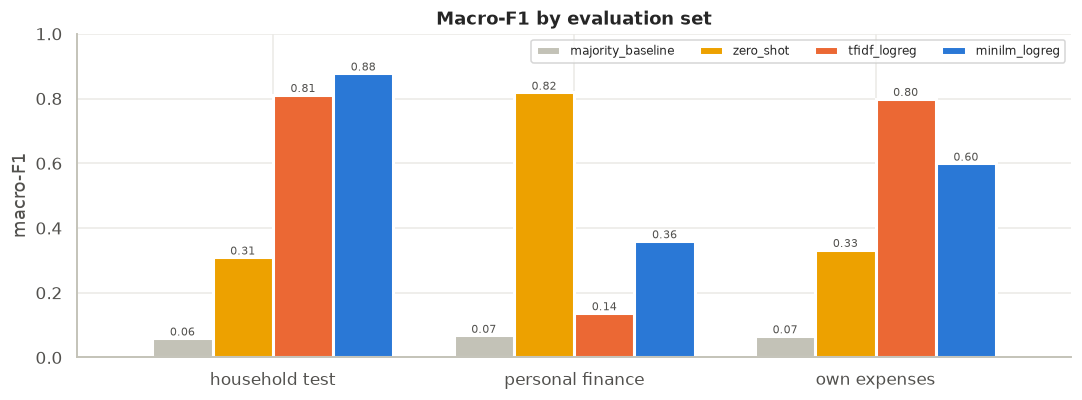

Chosen model beats majority baseline and zero-shot on held-out macro-F1: True


In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
pivot = results.pivot(index="eval set", columns="model", values="macro_f1").reindex(columns=model_order)
pivot = pivot.reindex(list(eval_sets))
colors = ["#c3c2b7", "#eda100", "#eb6834", "#2a78d6"]
pivot.plot.bar(ax=ax, color=colors, width=0.8, edgecolor="white", linewidth=2)
ax.set_title("Macro-F1 by evaluation set"); ax.set_ylabel("macro-F1"); ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0); ax.set_xlabel(""); ax.legend(ncol=4, loc="upper right", fontsize=8)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7, color="#52514e")
plt.tight_layout(); plt.show()
held_out = results[results["eval set"] == "household test"].set_index("model")
beats = all(held_out.loc[chosen_name, "macro_f1"] > held_out.loc[m, "macro_f1"] for m in ["majority_baseline", "zero_shot"])
print(f"Chosen model beats majority baseline and zero-shot on held-out macro-F1: {beats}")

## 2 · The chosen model on the held-out test split

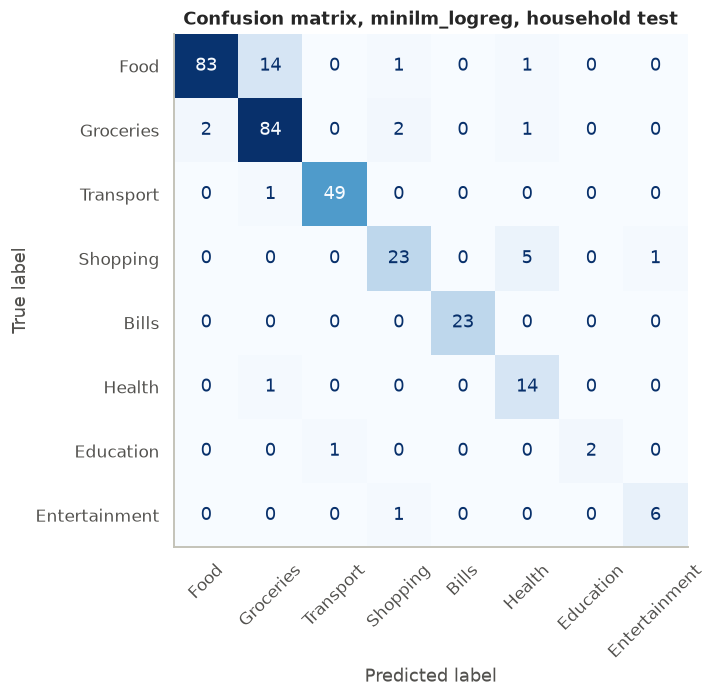

               precision    recall  f1-score   support

         Food      0.976     0.838     0.902        99
    Groceries      0.840     0.944     0.889        89
    Transport      0.980     0.980     0.980        50
     Shopping      0.852     0.793     0.821        29
        Bills      1.000     1.000     1.000        23
       Health      0.667     0.933     0.778        15
    Education      1.000     0.667     0.800         3
Entertainment      0.857     0.857     0.857         7

     accuracy                          0.902       315
    macro avg      0.897     0.877     0.878       315
 weighted avg      0.912     0.902     0.903       315



In [4]:
test_pred = chosen.predict(test[INPUT_COLUMNS])
present = [c for c in config.CATEGORIES if c in set(test.category)]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(confusion_matrix(test.category, test_pred, labels=config.CATEGORIES),
                       display_labels=config.CATEGORIES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix, {chosen_name}, household test"); ax.tick_params(axis="x", rotation=45)
ax.grid(False); plt.tight_layout(); plt.show()
print(classification_report(test.category, test_pred, labels=present, zero_division=0, digits=3))

## 3 · Transfer to other people's data

Same chosen model, no retraining. A drop is expected; the question is how big and why.

In [5]:
for set_name in ["personal finance", "own expenses"]:
    df = eval_sets[set_name]
    pred = chosen.predict(df[INPUT_COLUMNS])
    labels = [c for c in config.CATEGORIES if c in set(df.category)]
    print(f"===== {set_name}: {len(df)} rows =====")
    print(classification_report(df.category, pred, labels=labels, zero_division=0, digits=3))
    if set_name == "personal finance":
        by_merchant = (df.assign(pred=pred, correct=pred == df.category)
                       .groupby(["description", "category"]).agg(rows=("correct", "size"), share_correct=("correct", "mean"),
                                                                 predicted=("pred", lambda p: p.mode()[0]))
                       .sort_values("rows", ascending=False))
        print("Most frequent merchants and how the model labels them:")
        display(by_merchant.head(15).round(2))
    else:
        display(df.assign(predicted=pred)[["date", "description", "amount", "category", "predicted"]])

===== personal finance: 604 rows =====
               precision    recall  f1-score   support

         Food      0.464     1.000     0.634       155
    Groceries      0.000     0.000     0.000       105
    Transport      0.000     0.000     0.000        52
     Shopping      0.353     0.360     0.356       100
        Bills      1.000     0.292     0.452       144
Entertainment      0.575     0.958     0.719        48

    micro avg      0.472     0.462     0.467       604
    macro avg      0.399     0.435     0.360       604
 weighted avg      0.462     0.462     0.386       604

Most frequent merchants and how the model labels them:


,,rows,share_correct,predicted
description,category,,,
Grocery Store,Groceries,103,0.0,Food
Amazon,Shopping,59,0.0,Groceries
Hardware Store,Shopping,34,1.0,Shopping
Starbucks,Food,32,1.0,Food
American Tavern,Food,24,1.0,Food
Brewing Company,Food,23,1.0,Food
Gas Company,Bills,21,0.0,Food
Internet Service Provider,Bills,21,1.0,Bills
Phone Company,Bills,21,0.0,Shopping


===== own expenses: 5 rows =====
              precision    recall  f1-score   support

        Food      1.000     1.000     1.000         1
   Groceries      1.000     1.000     1.000         1
   Transport      1.000     1.000     1.000         1
       Bills      0.000     0.000     0.000         1
   Education      0.000     0.000     0.000         1

   micro avg      1.000     0.600     0.750         5
   macro avg      0.600     0.600     0.600         5
weighted avg      0.600     0.600     0.600         5



,date,description,amount,category,predicted
0,2026-11-02,Chai and paratha at campus dhaba,250,Food,Food
1,2026-11-03,Careem ride to university,480,Transport,Transport
2,2026-11-04,Milk eggs and bread from Imtiaz,1150,Groceries,Groceries
3,2026-11-05,Jazz mobile load,500,Bills,Health
4,2026-11-06,Printouts and spiral binding for assignment,300,Education,Shopping


In [6]:
# Two quick checks to explain the personal-finance drop.
pf = eval_sets["personal finance"]
neutral = pf.assign(amount=metadata["default_amount"])  # same amount for every row: removes the USD-vs-INR effect
print("Personal finance with real USD amounts:   ", {k: round(v, 3) for k, v in T.scores(pf.category, chosen.predict(pf[INPUT_COLUMNS])).items()})
print("Personal finance with one neutral amount: ", {k: round(v, 3) for k, v in T.scores(pf.category, chosen.predict(neutral[INPUT_COLUMNS])).items()})
print()
for word in ["grocery", "amazon"]:
    hits = train[train.description.str.lower().str.contains(word)]
    print(f"Training rows containing '{word}': {hits.category.value_counts().to_dict()}")

Personal finance with real USD amounts:    {'accuracy': 0.462, 'macro_f1': 0.36}


Personal finance with one neutral amount:  {'accuracy': 0.465, 'macro_f1': 0.355}

Training rows containing 'grocery': {'Food': 6, 'Groceries': 1}
Training rows containing 'amazon': {'Entertainment': 2}


### Why the scores drop outside the household data

**Personal finance (another person, USA).** The chosen model's macro-F1 falls from 0.878 on the household test to 0.360,
and here the zero-shot model (0.819) is far better than every trained model. The reasons are visible in the tables above:

- **Different wording.** This person's descriptions are merchant names ("Grocery Store", "BP", "Mortgage Payment"),
  which the household notes almost never contain. A trained model only knows the words of its training data.
- **The training labels teach the wrong lesson for this person.** In the household data the note "grocery" is labelled
  Food 6 times out of 7, so all 103 "Grocery Store" rows are predicted Food. "Amazon" appears only twice in training,
  both as an Amazon Prime subscription (Entertainment).
- **The currency is not the main cause.** Replacing every amount with one neutral value changes macro-F1 only from 0.360 to 0.355,
  so the drop comes from the text, not from USD vs INR amounts.
- **Zero-shot wins here** because it never learned one household's habits: it only compares meanings, and
  "Grocery Store" means groceries to anyone.

**Own expenses.** The file still holds the 5 example rows, so 3 of 5 correct (accuracy 0.6) says almost nothing yet.
The two misses are telling, though: "Jazz mobile load" (a Pakistani phone top-up) and "Printouts and spiral binding"
use words the Indian household data never used. This number becomes meaningful once real expenses are added, and it is the
best argument for the app's correction loop and retraining (Step 8).

## 4 · Twenty wrong predictions (household test)

In [7]:
proba = chosen.predict_proba(test[INPUT_COLUMNS])
errors = test.assign(predicted=test_pred, confidence=proba.max(axis=1))
errors = errors[errors.predicted != errors.category]
print(f"{len(errors)} wrong out of {len(test)} test rows")
wrong20 = errors.sample(min(20, len(errors)), random_state=config.RANDOM_SEED).sort_values("confidence", ascending=False)
wrong20[["description", "amount", "category", "predicted", "confidence"]].round(2)

31 wrong out of 315 test rows


,description,amount,category,predicted,confidence
36,Ginger + green chilli,20.0,Groceries,Food,0.94
70,Body mist,525.0,Shopping,Health,0.90
112,Kaju katli half kg,500.0,Food,Groceries,0.87
24,Finding next Job,100.0,Education,Transport,0.83
268,Dahi,32.0,Food,Groceries,0.80
26,French crossiant,80.0,Food,Health,0.71
267,Toothpaste Patanjali,160.0,Groceries,Shopping,0.70
253,For Family,3410.0,Shopping,Health,0.65
255,Bows,398.0,Shopping,Health,0.64
33,Bread,35.0,Food,Groceries,0.62


### Error types

The 20 mistakes above, grouped by hand (the labels are in the next cell so the grouping can be checked):

1. **Food vs Groceries boundary**: bread, dahi, srikhand, ginger, pickle. The same item is bought as a snack or for the
   kitchen, and the source labels are themselves inconsistent ("Bread" appears under both).
2. **Household and personal-care items**: body mist, toothpaste, bows, tap repair, cockroach spray, baking soda. They fit
   no category clearly and get scattered across Shopping, Health and Groceries.
3. **Words the model has never seen**: a brand ("Aqugurad PRV"), a book title ("Finding next Job"), a typo ("crossiant").
4. **Too vague to tell**: "For Family" says who the money was for, not what it bought. No model could get this right.

Several mistakes have high confidence (0.94 for "Ginger + green chilli"), so a threshold alone cannot catch every error:
the user's corrections are still needed.

In [8]:
error_type = {
    "Ginger + green chilli": "Food vs Groceries", "Kaju katli half kg": "Food vs Groceries", "Dahi": "Food vs Groceries",
    "Warna Srikhand half kg": "Food vs Groceries", "Warna Srikhand pav kg": "Food vs Groceries", "Bread": "Food vs Groceries",
    "Toast packet": "Food vs Groceries", "Pickle": "Food vs Groceries",
    "Body mist": "Household / personal care", "Toothpaste Patanjali": "Household / personal care", "Bows": "Household / personal care",
    "Math tap repair": "Household / personal care", "Cockroach injection": "Household / personal care",
    "Baking soda": "Household / personal care", "For Family": "Too vague",
    "3.4 Lit Petrol": "Unit word misleads",  # appears in the sample with some library versions
    "Finding next Job": "Unseen word", "French crossiant": "Unseen word", "Aqugurad PRV": "Unseen word",
}
wrong20["error_type"] = wrong20.description.map(error_type).fillna("(not grouped)")
wrong20.error_type.value_counts()

error_type
Food vs Groceries            10
Household / personal care     6
Unseen word                   3
Too vague                     1
Name: count, dtype: int64

## 5 · Choosing the confidence threshold

When the model is unsure, the app should ask the user to choose. To pick the cut-off **without using the
test split**, we use *out-of-fold* predictions on the training data: every training row is predicted by a
model that did not see it during 5-fold cross-validation.

**Rule:** the threshold is the lowest confidence at which predictions at or above it are **at least 90% correct**.
Below it, the app shows "please check".

In [9]:
oof_model = T.make_model(chosen_name, **metadata["settings"])
oof_proba = cross_val_predict(oof_model, train[INPUT_COLUMNS], train.category, cv=T.cv_splitter(), method="predict_proba")
oof_classes = np.array(sorted(train.category.unique()))
oof_pred, oof_conf = oof_classes[oof_proba.argmax(axis=1)], oof_proba.max(axis=1)

def threshold_curve(confidence: np.ndarray, correct: np.ndarray) -> pd.DataFrame:
    rows = []
    for t in np.round(np.arange(0.0, 0.96, 0.05), 2):
        kept = confidence >= t
        rows.append({"threshold": t, "accuracy_above": correct[kept].mean() if kept.any() else np.nan,
                     "share_auto_accepted": kept.mean()})
    return pd.DataFrame(rows)

oof_curve = threshold_curve(oof_conf, oof_pred == train.category.to_numpy())
test_curve = threshold_curve(proba.max(axis=1), test_pred == test.category.to_numpy())
TARGET = 0.90
threshold = float(oof_curve[oof_curve.accuracy_above >= TARGET].threshold.min())
print(f"Chosen threshold: {threshold}")
pd.concat({"train (out-of-fold)": oof_curve.set_index("threshold"), "test": test_curve.set_index("threshold")}, axis=1).round(3)

Chosen threshold: 0.6


train (out-of-fold)                               test  \
               accuracy_above share_auto_accepted accuracy_above   
threshold                                                          
0.00                    0.832               1.000          0.902   
0.05                    0.832               1.000          0.902   
0.10                    0.832               1.000          0.902   
0.15                    0.832               1.000          0.902   
0.20                    0.832               1.000          0.902   
0.25                    0.834               0.998          0.902   
0.30                    0.835               0.995          0.904   
0.35                    0.838               0.983          0.910   
0.40                    0.847               0.966          0.910   
0.45                    0.857               0.948          0.916   
0.50                    0.870               0.917          0.924   
0.55                    0.888               0.873          0.936   
0.60                    0.901               0.838          0.948   
0.65                    0.910               0.807          0.964   
0.70                    0.925               0.761          0.973   
0.75                    0.933               0.709          0.980   
0.80                    0.951               0.643          0.978   
0.85                    0.966               0.566          0.985   
0.90                    0.981               0.498          0.994   
0.95                    0.995               0.349          1.000   

                               
          share_auto_accepted  
threshold                      
0.00                    1.000  
0.05                    1.000  
0.10                    1.000  
0.15                    1.000  
0.20                    1.000  
0.25                    1.000  
0.30                    0.997  
0.35                    0.987  
0.40                    0.984  
0.45                    0.978  
0.50                    0.956  
0.55                    0.937  
0.60                    0.914  
0.65                    0.883  
0.70                    0.835  
0.75                    0.784  
0.80                    0.711  
0.85                    0.619  
0.90                    0.492  
0.95                    0.371

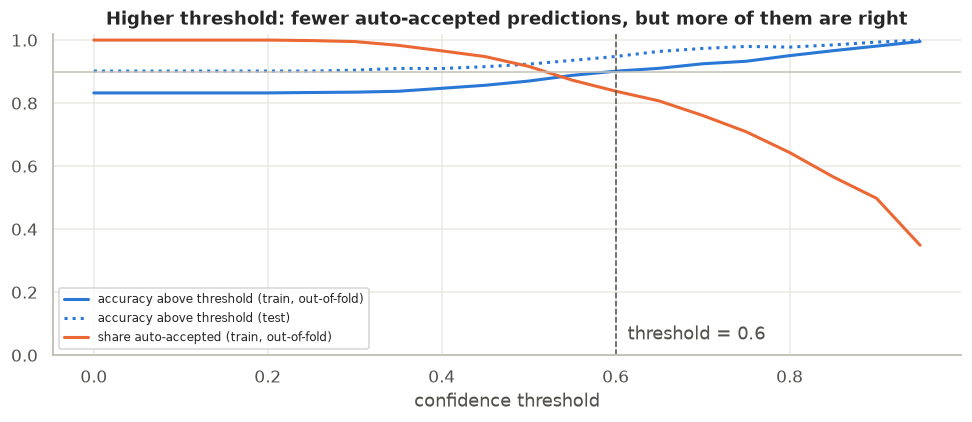

On the test split at 0.6: 91% auto-accepted, 94.8% of those correct; 9% sent to the user to check


In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(oof_curve.threshold, oof_curve.accuracy_above, color="#2a78d6", linewidth=2, label="accuracy above threshold (train, out-of-fold)")
ax.plot(test_curve.threshold, test_curve.accuracy_above, color="#2a78d6", linewidth=2, linestyle=":", label="accuracy above threshold (test)")
ax.plot(oof_curve.threshold, oof_curve.share_auto_accepted, color="#eb6834", linewidth=2, label="share auto-accepted (train, out-of-fold)")
ax.axvline(threshold, color="#52514e", linestyle="--", linewidth=1)
ax.axhline(TARGET, color="#c3c2b7", linewidth=1)
ax.text(threshold, 0.05, f"  threshold = {threshold}", color="#52514e")
ax.set_xlabel("confidence threshold"); ax.set_ylim(0, 1.02); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Higher threshold: fewer auto-accepted predictions, but more of them are right")
plt.tight_layout(); plt.show()
at_t = test_curve.set_index("threshold").loc[threshold]
print(f"On the test split at {threshold}: {at_t.share_auto_accepted:.0%} auto-accepted, "
      f"{at_t.accuracy_above:.1%} of those correct; {1 - at_t.share_auto_accepted:.0%} sent to the user to check")

### Save the threshold and test scores

The threshold goes into `src/config.py` (used by `predict.py`); the test accuracy goes into
`models/metadata.json` (the monitoring page compares live accuracy against it).

In [11]:
config_path = config.ROOT / "src" / "config.py"
text = config_path.read_text()
config_path.write_text(re.sub(r"CONFIDENCE_THRESHOLD = .*", f"CONFIDENCE_THRESHOLD = {threshold}", text))
test_scores = T.scores(test.category, test_pred)
T.update_metadata(test_accuracy=round(test_scores["accuracy"], 4), test_macro_f1=round(test_scores["macro_f1"], 4),
                  confidence_threshold=threshold,
                  test_date_range=[str(test.date.min().date()), str(test.date.max().date())])

{'model_name': 'minilm_logreg',
 'model_version': 'v1',
 'features': ['minilm_embedding(clean description, 384 dims)',
  'log1p_amount',
  'weekday',
  'is_weekend'],
 'settings': {'C': 10, 'class_weight': 'balanced'},
 'train_date_range': ['2015-01-01', '2018-03-15'],
 'train_rows': 1258,
 'label_distribution': {'Food': 367,
  'Groceries': 347,
  'Transport': 252,
  'Shopping': 104,
  'Bills': 51,
  'Health': 74,
  'Education': 20,
  'Entertainment': 43},
 'cv_macro_f1': 0.7858,
 'default_amount': 60.0,
 'sklearn_version': '1.9.1',
 'saved_at': '2026-11-23T21:48:27',
 'test_accuracy': 0.9016,
 'test_macro_f1': 0.8784,
 'confidence_threshold': 0.6,
 'test_date_range': ['2018-03-17', '2018-09-20']}

## What I learned